# JavaScript Modules

A comprehensive guide to modular JavaScript — why modules exist, how ES Modules, CommonJS, AMD, and UMD work, and how to use modules in Node.js and the browser.

## Table of Contents

- [Module 01: Modular JavaScript](#module-01-modular-javascript)
- [Module 02: ECMAScript Modules](#module-02-ecmascript-modules)
- [Module 03: CommonJS Modules](#module-03-commonjs-modules)
- [Module 04: Modules in Node.js](#module-04-modules-in-nodejs)
- [Module 05: Modules in the Browser](#module-05-modules-in-the-browser)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Modular JavaScript

_An introduction to why JavaScript needs modules, a brief history of how code was written without them, and an overview of the three main module standards: ES Modules, CommonJS, and AMD._

### Version Notes

- ECMAScript 2015 (ES6) and later
- Node.js v16.18.0 (LTS) / npm 8.9.12
- For browsers: know which browsers you're targeting — you may write modern JS and compile down to an older version
- For Node.js: versioning is more consistent

### The Evolution of JavaScript in the Browser

Before modules, JavaScript was written inline in HTML, then extracted into separate files loaded with `<script>` tags. The problems that emerged:

**Inline event handler (earliest form)**
```html
<button onclick="alert('hello world')">Click me</button>
```

**Separate function (marginally better)**
```html
<button onclick="clickHandler">Click me</button>
<script>
function clickHandler() { alert("Hello World"); }
</script>
```

**jQuery era — DOM-ready pattern**
```html
<script src="jquery.js"></script>
<script src="jquery.animations.js"></script>
<script src="jquery.plugin.js"></script>
<script src="site.js"></script>
<script>
$(document).ready(function () {
  $("theButton").on("click", function () {
    alert("Hello World");
  });
});
</script>
```

The `$(document).ready()` wrapper was the workaround for scripts loading before the DOM was ready — a symptom of having no real module system.

### Why Modules Are Needed

With modern JavaScript, a single entry point (`main.js`) pulls in all dependencies. Without a module system the browser must load each `<script>` in the right order, and everything ends up sharing the same global scope.

With a module system, only one `<script>` tag is needed and all dependency resolution happens at the module level.


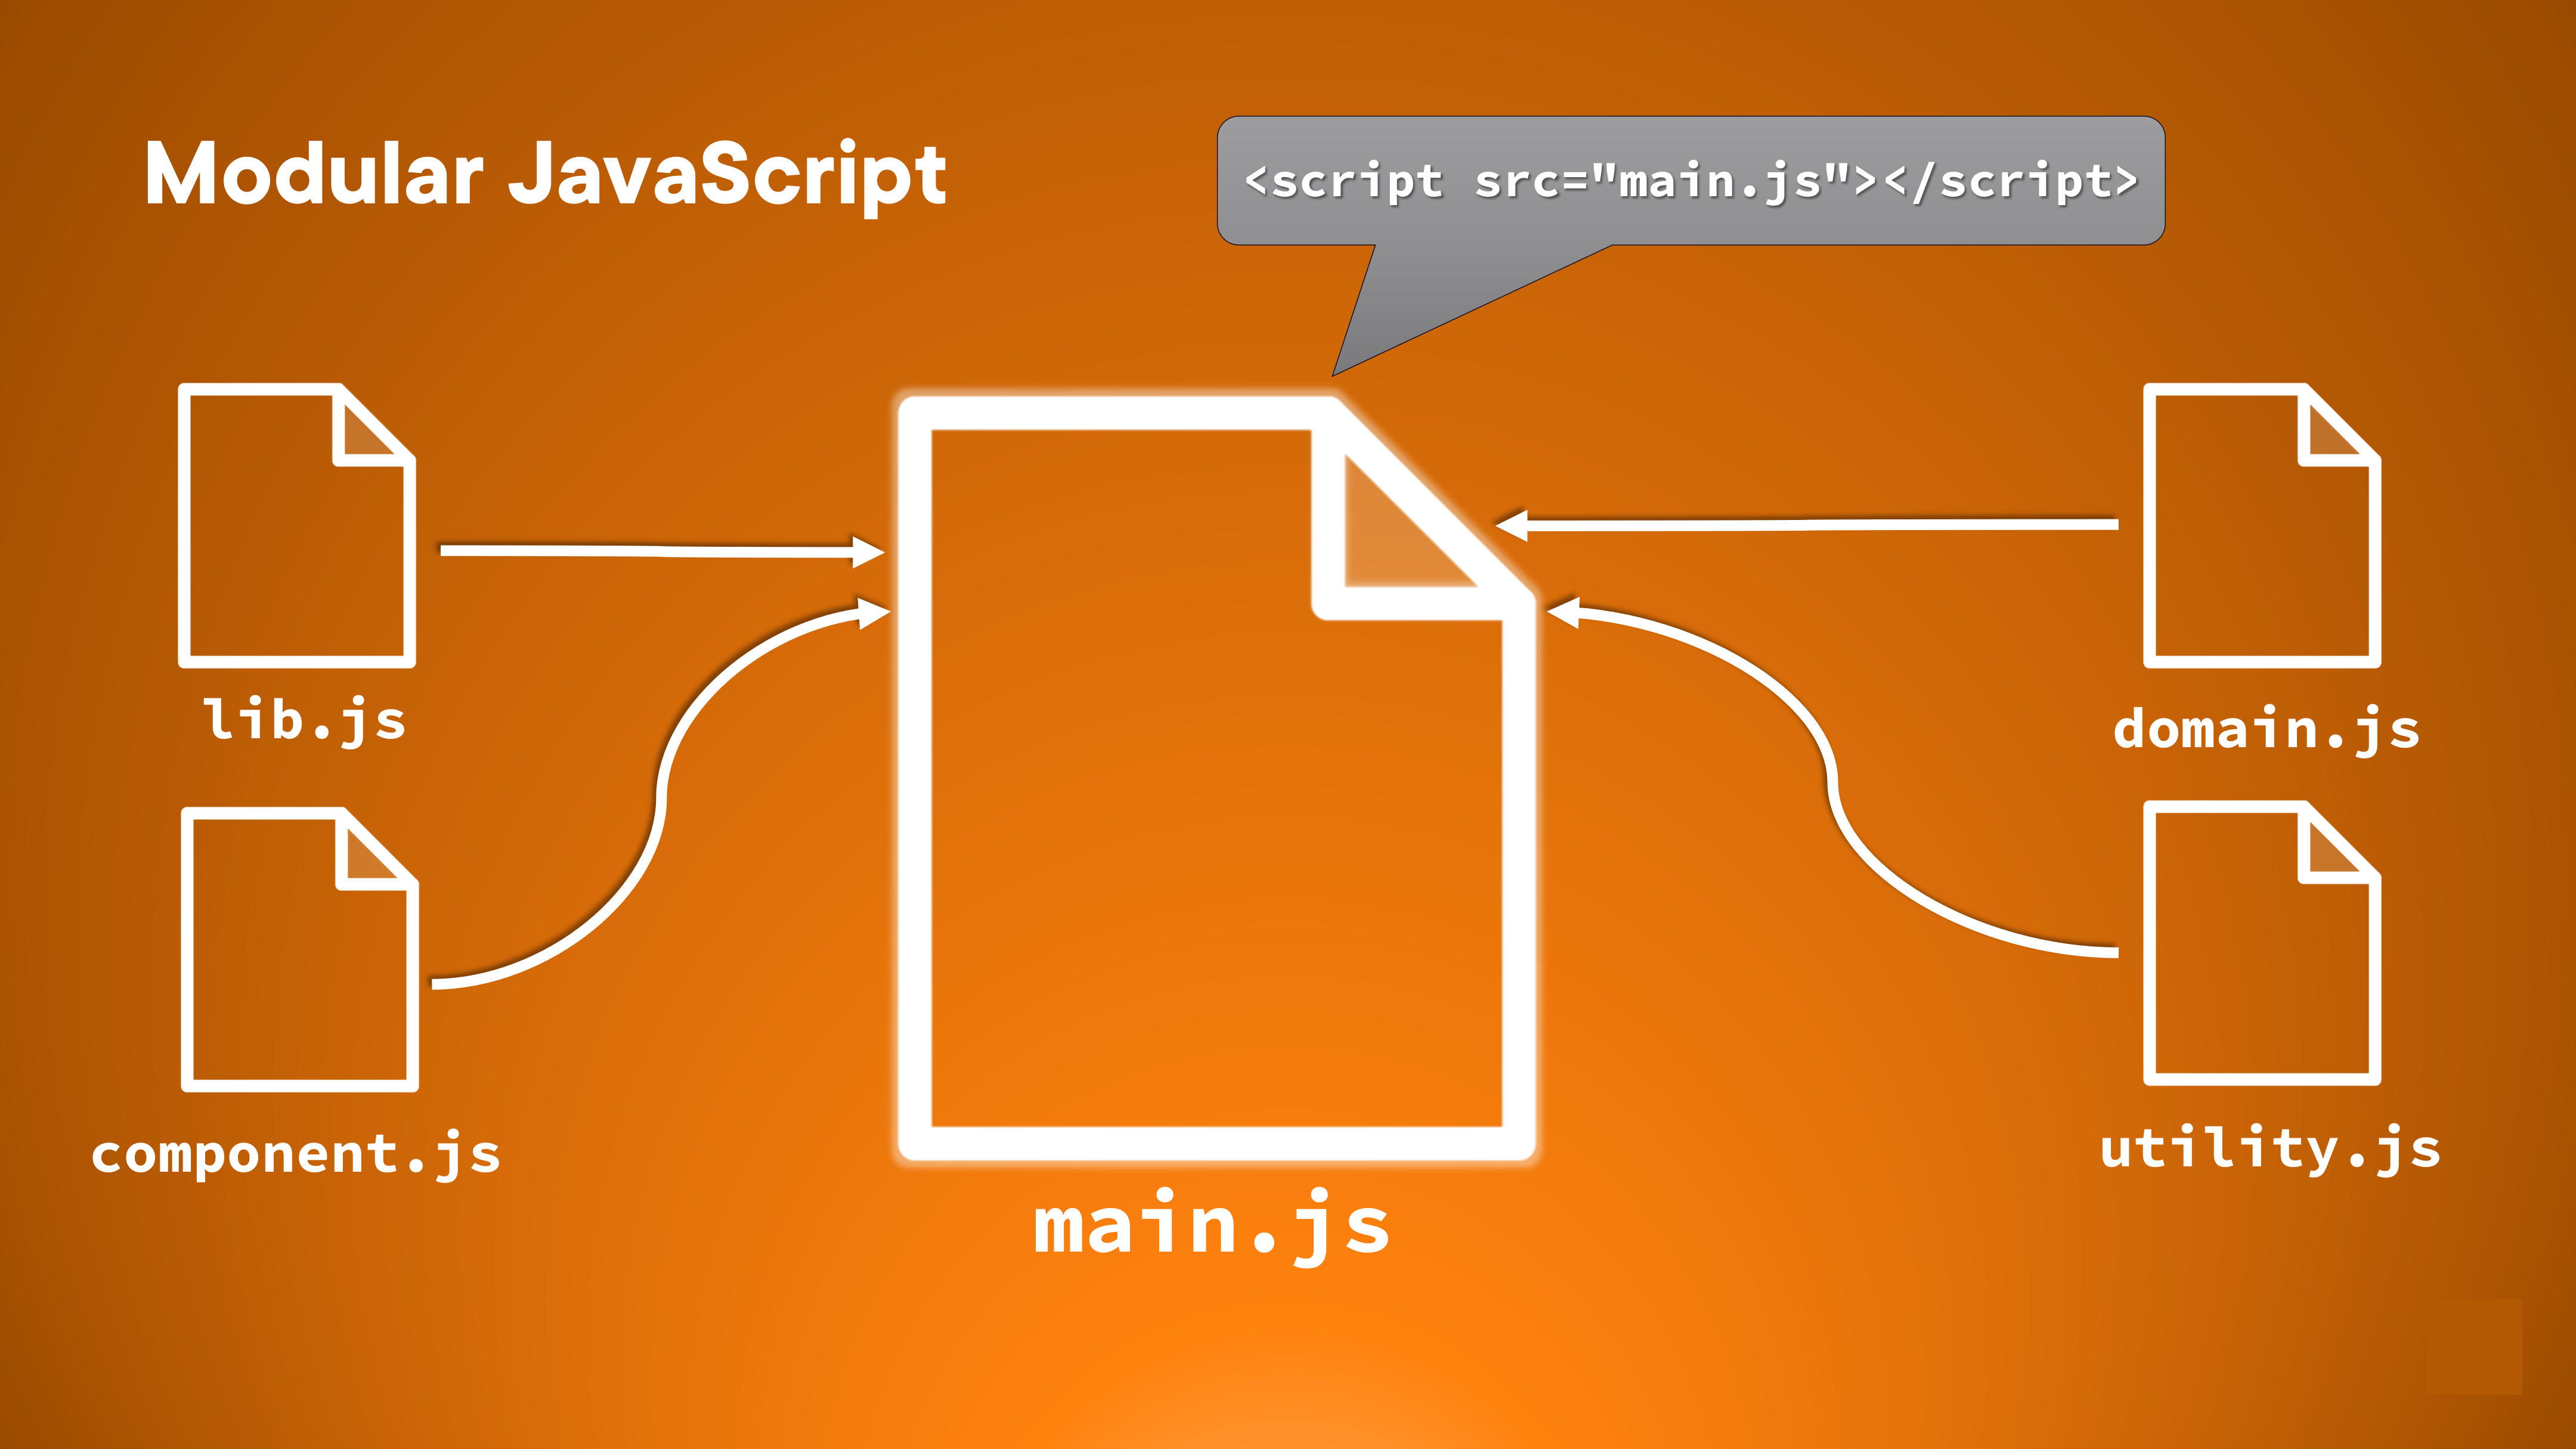

In [2]:
render_diagram(Path("assets/01-modular-js-structure.png"))

### Why Modules Are Hard

Three root causes made modular JavaScript difficult for a long time:

- JavaScript was not designed for large-scale applications
- Deferring scripts (`defer`, `async`) is not a real module solution
- No single agreed-upon module format — the community fragmented into competing standards

### The Four Module Standards

| Standard | Where Used | Purpose |
|---|---|---|
| **ES Modules** | All platforms (the future) | Native ECMAScript standard; `import`/`export` syntax |
| **CommonJS** | Mostly server-side (Node.js) | `require()`/`module.exports`; synchronous, on-demand loading |
| **AMD** | Client-side (older libraries) | Asynchronous dependency injection via `define()` |
| **UMD** | Cross-environment libraries | Wrapper that detects the environment and uses the right format |

#### ES Modules (the standard)

```js
// utils.js
export function roundMoney(value) {
  return Math.round(value * 100) / 100;
}

// calculateTax.js
import { roundMoney } from "./utils.js";
export default function calculateTax(lineTotal) {
  return {
    preTax: roundMoney(lineTotal),
    totalWithTax,
    taxRate
  };
}
```

#### CommonJS (Node.js default)

```js
// utils.js
module.exports = function roundMoney(value) {
  return Math.round(value * 100) / 100;
};

// calculateTax.js
const roundMoney = require("./utils.js");
module.exports = function calculateTax(lineTotal) {
  return { preTax: roundMoney(lineTotal), totalWithTax, taxRate };
};
```

#### AMD (asynchronous, older)

```js
// utils.js
define([], function () {
  return function roundMoney(value) {
    return Math.round(value * 100) / 100;
  };
});

// calculateTax.js
define(["./utils.js"], function (utils) {
  return { preTax: utils.roundMoney(lineTotal), totalWithTax, taxRate };
});
```

#### UMD (universal — detects the environment at runtime)

```js
(function (root, factory) {
  if (typeof define === 'function' && define.amd) {
    define(['exports', './utils.js'], factory);  // AMD
  } else if (typeof exports === 'object' && typeof exports.nodeName !== 'string') {
    factory(exports, require('./utils.js'));       // CommonJS
  } else {
    factory((root.commonJsStrict = {}), root.utils); // Browser globals
  }
})(typeof self !== 'undefined' ? self : this, function (exports, utils) {
  // module body
});
```

### What About TypeScript?

TypeScript compiles to JavaScript. ES Modules are the default output format, but the TypeScript compiler can be configured to emit CommonJS or AMD instead.

### Demo: Adding Modules

Demonstrates converting a single-file script into a multi-file ES Module project. See [`javascript-modules-demos/01-adding-modules/`](javascript-modules-demos/01-adding-modules/) for the before/after project.

```js
// after/index.js
import { calculateTax } from "./calculateTax.js";
import { roundMoney } from "./roundMoney.js";

for (let x = 0; x < 10; ++x) {
  const invoiceTotal = Math.random() * 1000;
  const { postTax, taxRate } = calculateTax(invoiceTotal);
  console.log(`Total: $${roundMoney(invoiceTotal)} X ${taxRate} = $${postTax}`);
}
```

The `before/` version keeps all logic in a single `index.js`; the `after/` version splits it into `calculateTax.js` and `roundMoney.js` and imports them explicitly.

---

## Module 02: ECMAScript Modules

_Deep dive into the native ES Module standard: history, exporting values and objects, importing with different syntaxes, cascading (re-exporting) imports, and module lifetime semantics._

### History of ECMAScript Modules

ECMAScript is the official standard name; JavaScript is the name that stuck. ES Modules were introduced in **ECMAScript 2015 (ES6)** after years without a native module system. Earlier versions (ES3, ES5) had no module support at all.

Key ECMAScript versions:

| Year | Version |
|------|---------|
| 1997 | First Edition |
| 1999 | ECMAScript 3 |
| 2009 | ECMAScript 5 |
| 2015 | **ECMAScript 2015 (ES6) — modules introduced** |
| 2016–2022 | Annual releases |

ECMAScript 4 was abandoned. Annual releases have been the cadence since 2015.

**Browser support:** transpilers (e.g. Babel) were needed initially. Today, ES Modules are natively supported in all modern browsers and Node.js.

### Importing

The `import` statement is static — it is resolved before any code runs. All forms:

```js
import path from "path";               // built-in or installed package
import user from "./user.js";          // .js file relative path
import name from "./utils/name.js";    // nested path
import utils from "./utils";           // shortcut: resolves to ./utils/index.js (Node.js only)

import * as ModuleName from "./user.js";     // namespace import — all exports as one object
import user from "./user.js";               // default export
import { showUser } from "./user.js";       // named export
import user, { showUser } from "./user.js"; // default + named together
```

> The directory shortcut (`import utils from "./utils"`) is not supported by default in Node.js without the full `./utils/index.js` path unless `package.json` exports are configured.

### Exporting

Exports can be attached inline to declarations or collected at the bottom of a file.

```js
// Default export
export default { name: "Shawn" };
export default "Shawn";                         // any value

// Named exports — inline
export const user = { name: "Shawn" };
export let birthdate = new Date();
export const theName = "Shawn";
export let users = [{ name: "Shawn" }];
export class User { user = "Shawn" }
export function formatUser(user) { /* ... */ }

// Named exports — separate declaration and export
let user = { name: "Shawn" };
export { user };

// Export as default from a let
let user = { name: "Shawn" };
export { user as default };

// Multiple exports at once
export { user as default, showUser };
```

### Aggregating (Re-exporting) Exports

A module can re-export symbols from other modules, acting as a barrel/index file:

```js
// Verbose form — import then re-export
import { name } from "./name.js";
export let theName = name;

// Shorthand aggregate
export { name } from "./name.js";

// Aggregate everything
export * from "./name.js";
```

This pattern is commonly used in an `index.js` inside a directory to present a clean public API for a feature or package.

### Module Concepts

#### ES Modules and Dependency Injection

ES Modules are not dependency injection. Imports rely on static knowledge of where a module is constructed. They can substitute for DI in simple cases but don't provide runtime binding or inversion of control.

#### Module Lifetime — Modules Load Once

Each module is loaded and evaluated **once**, regardless of how many times it is imported. Subsequent imports return the same module instance. This means:

- Exported **primitives** are copied at import time — reassigning them in one importer does not affect others.
- Exported **objects** are shared by reference — mutating an exported object in one importer is visible to all other importers.

```js
// user.js
export default { name: "Hello" };

// index.js
import x from "./user.js";
console.log(x.name);  // "Hello"
x.name = "Goodbye";
console.log(x.name);  // "Goodbye"

import y from "./user.js";
console.log(y.name);  // "Goodbye"  ← same object, mutation is shared
```

The import binding is always `const` — you cannot reassign `x = somethingElse`. But you can mutate the object `x` points to.

#### Working Around Shared Mutation

Use a factory function or a class when you need independent instances:

```js
// Factory pattern — each caller gets a fresh object
export default function () {
  return { name: "Hello" };
}

// Class pattern
export class User {
  name = "Hello";
}
```

### Demo: ES Module Importing and Exporting

Demonstrates named exports, default exports, aggregated exports, and module lifetime. See [`javascript-modules-demos/02-es-modules/`](javascript-modules-demos/02-es-modules/) for the before/after project.

```js
// after/index.js
import quux, { capitalize, favoriteColors } from "./utils.js";
import User, { getTeam, sortTeam } from "./auth/index.js";

console.log(`${quux.appName} v${quux.version}`);
console.log(capitalize("Hello World"));
favoriteColors.forEach((c) => console.log(c));

const user = new User("Shawn", "Wildermuth");
console.log(user.format());

const team = getTeam();
sortTeam(team);
team.forEach(t => console.log(t.format()));

// Re-importing the same module returns the same shared instance
import { getTeam as getTeam2 } from "./auth/index.js";
const team2 = getTeam2();  // same array as team — mutation visible here
```

The `auth/index.js` file aggregates exports from `auth/users.js`, providing a single entry point for the `auth` feature.

---

## Module 03: CommonJS Modules

_CommonJS is the original server-side JavaScript module system — synchronous, on-demand loading via `require()` and `module.exports`. It predates ES Modules by six years and is still the default in Node.js._

### What Is CommonJS?

CommonJS started as **ServerJS**, a proposal to solve server-side JavaScript module loading before ES Modules existed. It extended beyond Node.js to several other environments:

- **Node.js** — still the default module format for `.js` files
- **Electron** — desktop apps built on Node.js
- **RequireJS** — browser-side CommonJS-compatible loader
- **MongoDB / CouchDB** — embedded JavaScript engines
- **CommonJS for PHP** — server-side PHP runtime

CommonJS is not part of the ECMAScript standard, though many of the same people are involved.

### Importing with CommonJS

`require()` is a function call — it loads a module **on demand** at the point in code where it is called, unlike ES Module `import` which is hoisted and resolved statically.

```js
// index.js

// Import the entire export
const lib = require("./lib.js");
console.log(lib());

// Destructure a named export
const { firstName } = require("./lib.js");
console.log(firstName);

// Inline property access — require() is just a function call
console.log(require("./lib.js").firstName);
```

Key difference from ES Modules: `require()` can appear anywhere in code, including inside conditionals or functions.

### Exporting with CommonJS

`module.exports` is the object that `require()` returns. It can be replaced entirely or augmented with properties.

```js
// Export a default function
module.exports = function () {
  return "From Lib";
};

// Export named properties
module.exports.firstName = "Shawn";
```

> **Pitfall:** Setting `module.exports` to a function and then adding properties to it works — but the named properties end up as properties on the function object, which can be surprising.

**Preferred pattern — build an export object explicitly:**

```js
class User {
  firstName = "";
  constructor(firstName) { this.firstName = firstName; }
}

const appName = "SomeApp";
function writeUser(user) { console.log(user.firstName); }

// Collect everything and assign once
module.exports = { User, appName, writeUser };
```

This avoids the function-as-export-object trap and makes the public API explicit.

### Cascading Imports in CommonJS

A CommonJS module can `require()` another module and re-export it, either as a named property or merged via spread:

```js
// Simple re-export of a whole module
module.exports.user = require("./user");

// Merge-and-re-export pattern
const echoLib = function () { return "From Lib"; };
const firstName = "Shawn";
const user = require("./user");

module.exports = {
  echoLib,
  firstName,
  ...user   // spread all exports from ./user into this module's exports
};
```

### Supporting Multiple Module Formats — UMD

When a library needs to work in AMD, CommonJS, and browser globals simultaneously, a **Universal Module Definition (UMD)** wrapper detects the environment at runtime:

```js
(function (root, factory) {
  if (typeof define === "function" && define.amd) {
    // AMD
    define(["exports"], factory);
  } else if (typeof exports === "object" && typeof exports.nodeName !== "string") {
    // CommonJS
    factory(exports);
  } else {
    // Browser globals
    factory((root.myModuleName = {}), root.b);
  }
})(typeof self !== "undefined" ? self : this, function (exports) {
  exports.appName = "SomeApp";
  exports.writeUser = function (user) { /* ... */ };
});
```

UMD is still found in older libraries but has largely been replaced by the ES Module + CommonJS dual-publish pattern in modern packages.

### Demo: CommonJS Importing and Exporting

Demonstrates `require()`, `module.exports`, and cascading imports. See [`javascript-modules-demos/03-commonjs-modules/`](javascript-modules-demos/03-commonjs-modules/) for the before/after project.

```js
// after/index.js
const { sumBy } = require("lodash");
const { calculateTax, Invoice } = require("./invoices/index.js");

const invoices = [];
for (let x = 0; x < 10; ++x) {
  invoices.push(new Invoice(Math.random() * 1000));
}

invoices.forEach((invoice) => {
  if (calculateTax(invoice)) {
    console.log(`Total: $${invoice.subtotal} X ${invoice.tax}% = $${invoice.total}`);
  }
});

console.log(`Grand Total: $${sumBy(invoices, "total")}`);
```

The `invoices/index.js` file aggregates exports from `Invoice.js` and `calculateTax.js` into one entry point.

---

## Module 04: Modules in Node.js

_How Node.js handles both CommonJS and ES Modules, how to opt into ES Modules via `package.json`, mixing the two formats, and using npm packages._

### Node.js Module Defaults and File Extensions

Node.js defaults to **CommonJS** for `.js` files. Two file-extension shortcuts exist to force a specific format regardless of `package.json`:

| Extension | Format |
|-----------|--------|
| `.js` | Determined by `package.json` `"type"` field (default: CommonJS) |
| `.mjs` | Always ES Module |
| `.cjs` | Always CommonJS |

```js
// Default: CommonJS
const lib = require("./lib.js");

// Dynamically importing an ES Module file from CommonJS
import("./lib.mjs").then((lib) => {
  console.log(lib.firstName);
  console.log(lib.appName);
});
```

### Opting Into ES Modules via package.json

Setting `"type": "module"` in `package.json` makes all `.js` files in the project ES Modules by default.

```json
{
  "name": "testing",
  "version": "1.0.0",
  "main": "index.js",
  "type": "module",
  "scripts": {
    "start": "node index.js"
  },
  "dependencies": {
    "rxjs": "^7.5.7"
  }
}
```

Once opted in, `import`/`export` syntax works in `.js` files, and CommonJS files must use the `.cjs` extension:

```js
// ES Module syntax — now works in .js
import { firstName, appName } from "./lib.js";
console.log(firstName);
console.log(appName);

// Can still import a CommonJS file using .cjs extension
import { firstName, appName } from "./lib.cjs";
```

### NPM Packages and Module Formats

Most npm packages are CommonJS, but the distinction is usually transparent to the consumer:

- Many modern packages ship **both** CommonJS and ES Module builds (dual-publish)
- When using ES Modules in your project, `import` from npm packages just works — Node.js resolves the right format automatically
- If a package is ESM-only and you're in a CommonJS project, you'll need dynamic `import()` or to opt into `"type": "module"`

> **For new projects:** opt into ES Modules from the start. They are the standard and the future.

### Demo: Modules in Node.js

Demonstrates CommonJS and ES Modules side-by-side in Node.js, including mixing `.cjs` files with an ES Module project. See [`javascript-modules-demos/04-nodejs-modules/`](javascript-modules-demos/04-nodejs-modules/) for the before/after project.

```js
// after/index.js — ES Module project (type: module in package.json)
import http from "http";
import routes from "./routes.js";

const PORT = process.env.PORT || 5000;

const server = http.createServer((req, res) => {
  routes.forEach((r) => {
    if (r.pattern === req.url && req.method === "GET") {
      res.writeHead(200, { "Content-Type": "application/json" });
      res.write(JSON.stringify(r.result));
      res.end();
    }
  });
  if (!res.writableEnded) {
    res.writeHead(404);
    res.end(JSON.stringify({ message: "Route not found" }));
  }
});

server.listen(PORT, () => console.log(`server started on port: ${PORT}`));
```

The `people.cjs` file in this demo uses CommonJS syntax and is imported into the ES Module project using the `.cjs` extension.

---

## Module 05: Modules in the Browser

_How browsers handle JavaScript, why global scope collisions are a problem, module bundlers and tree shaking, and the native `type="module"` script tag._

### How the Browser Handles JavaScript

Browsers have a layered architecture for executing JavaScript:


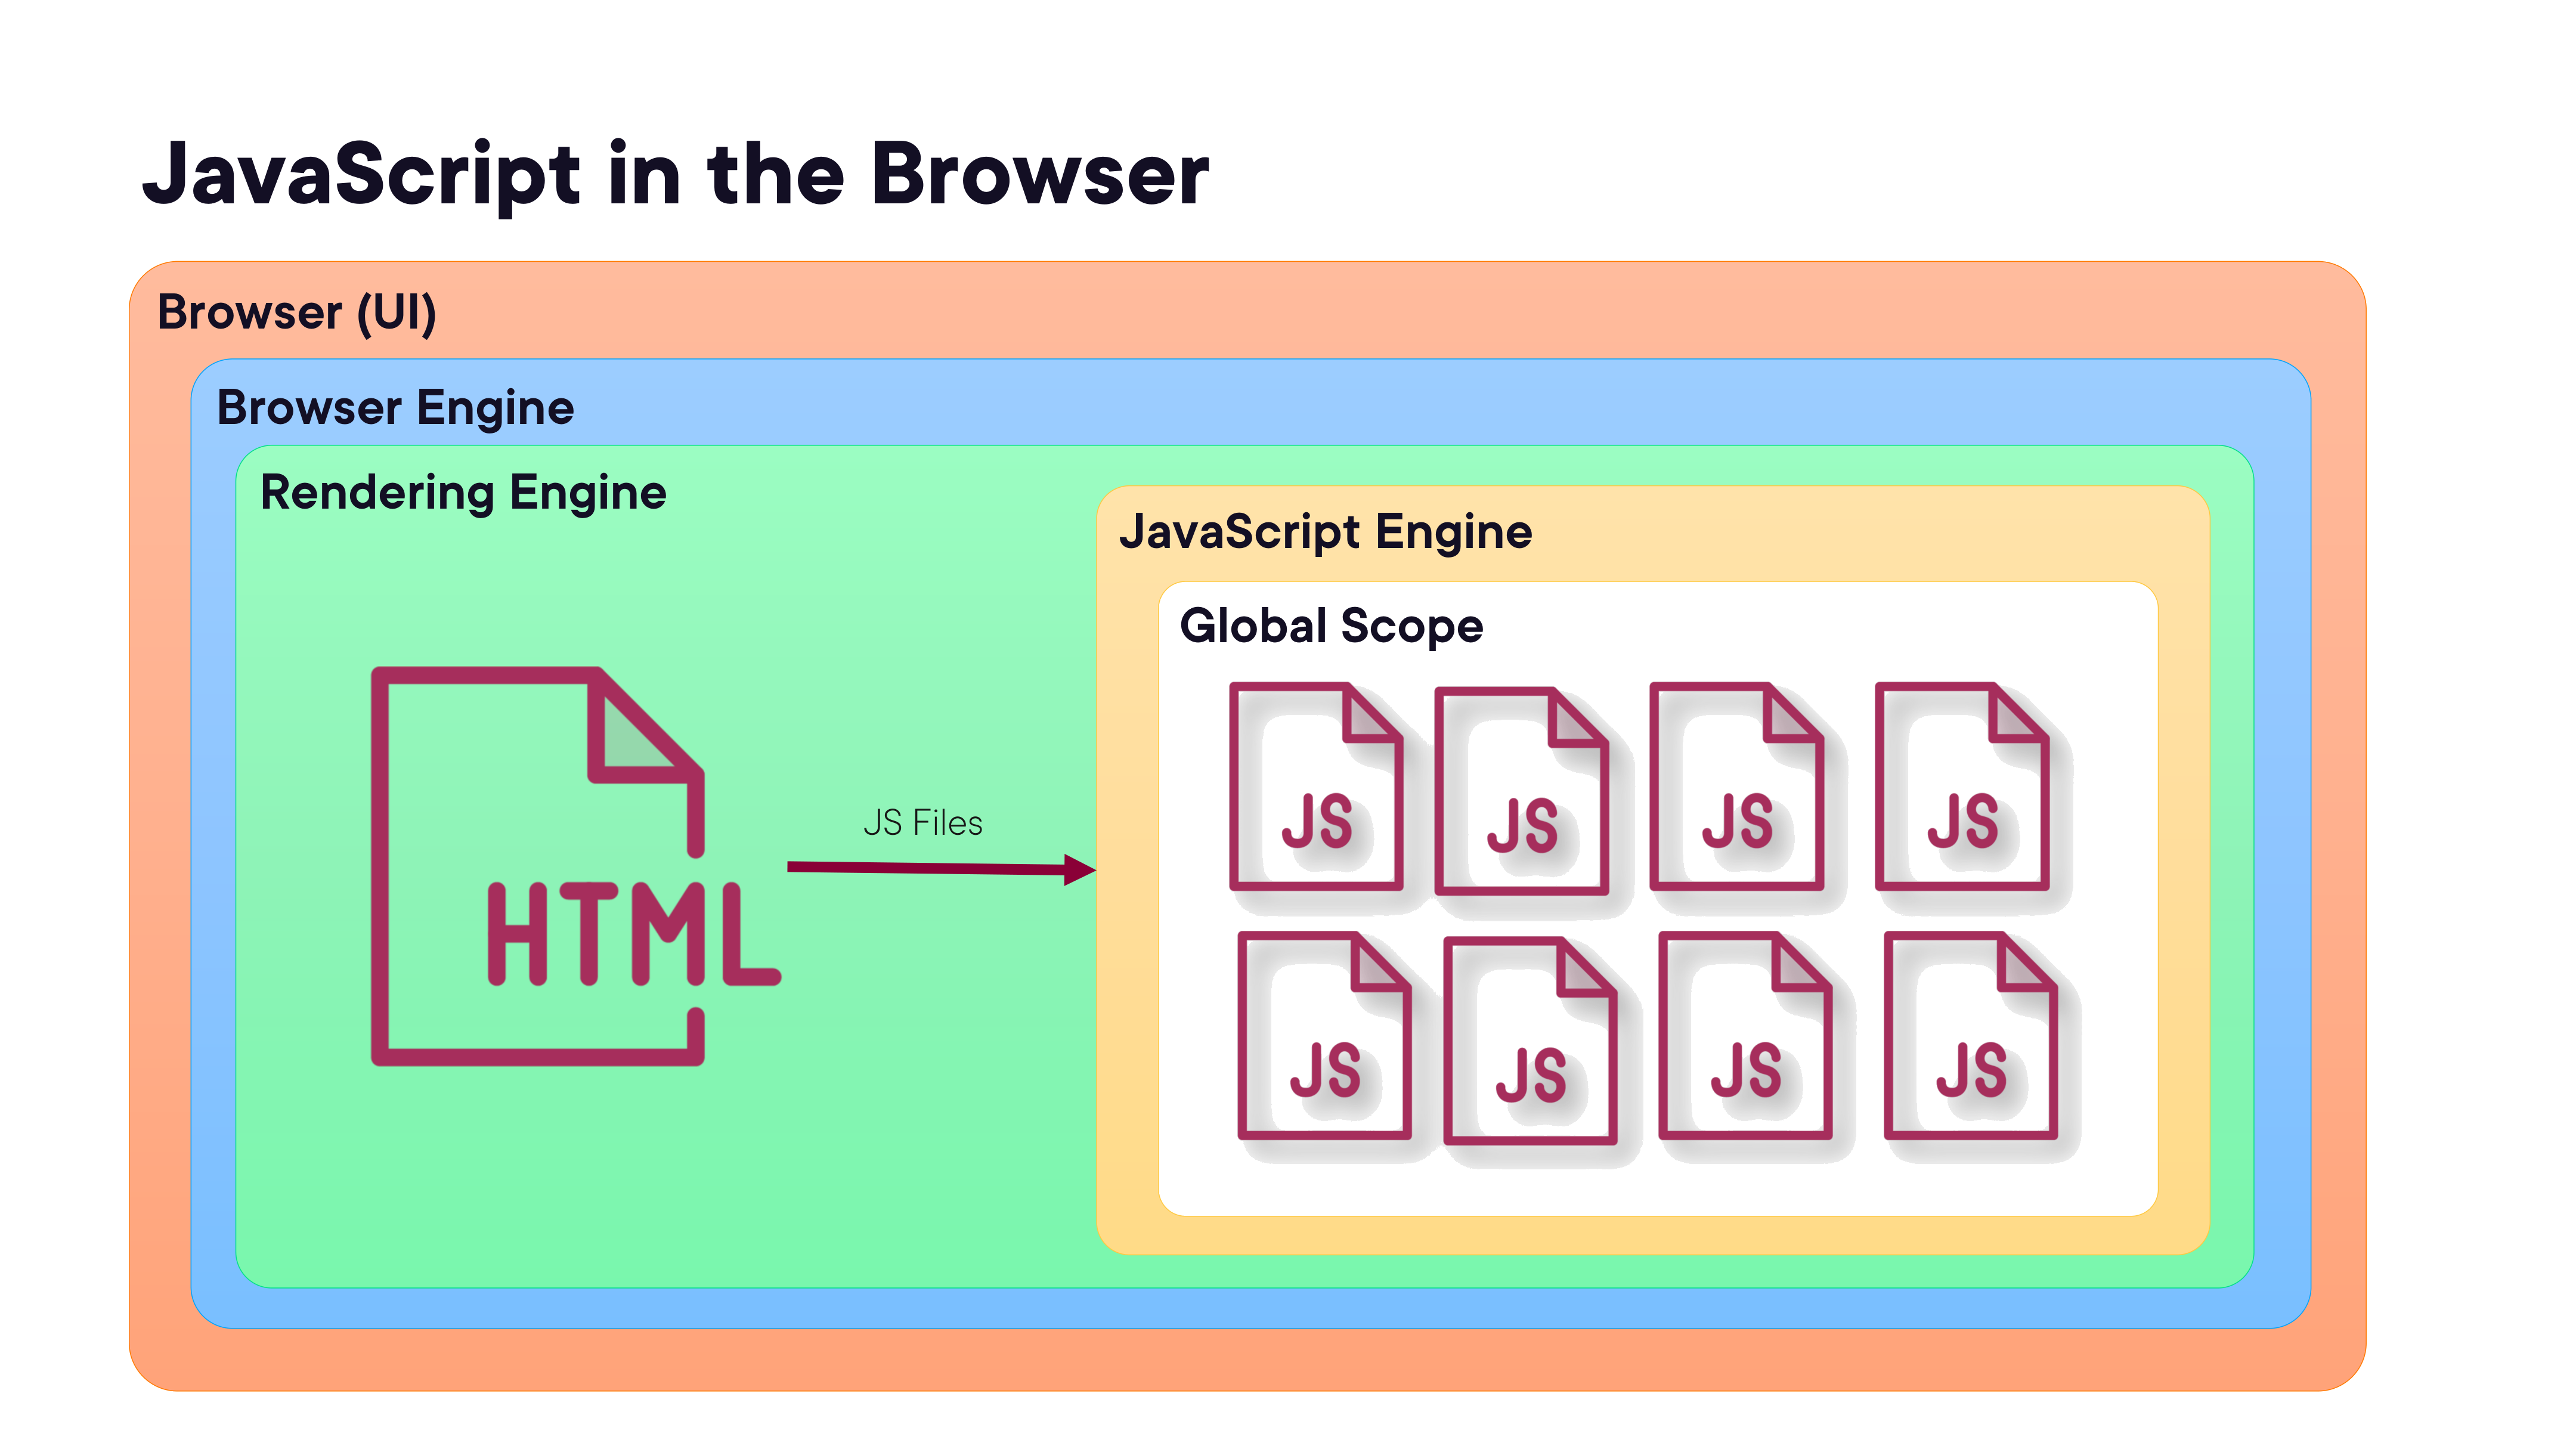

In [3]:
render_diagram(Path("assets/02-browser-architecture.png"))

The HTML document is parsed by the **Rendering Engine**; JS files referenced in `<script>` tags are handed to the **JavaScript Engine**, which executes them all in the same **Global Scope**. There is no isolation between files by default.

#### The Global Scope Problem

```html
<script src="./site.js"></script>
<script src="./client.js"></script>
```

```js
// site.js
const title = document.getElementById("title");
title.innerHTML = "Testing Scope";

// client.js
const title = document.head.title;  // ERROR — "title" already declared!
title.textContent = "Testing Scope";
```

Loading multiple scripts feels like separate modules, but they share the same global scope. Name collisions are runtime errors.

#### Pre-module Workarounds

Two common patterns to fake isolation before ES Modules:

```js
// Namespacing with objects
const Working = {
  showStuff() { console.log(this.appName); },
  appName: "An App"
};
Working.showStuff();

// IIFE — Immediately Invoked Function Expression
(function () {
  const title = document.head.title;
  title.textContent = "Testing Scope";
})();
```

The IIFE uses function scope to isolate variables. Both patterns are brittle — they rely on developer discipline rather than language enforcement.

### Module Bundlers

Module bundlers solve the browser's global scope problem by combining all modules and their dependencies into a single (or small set of) optimised JavaScript file(s) suitable for the browser.

**Popular bundlers:**
- **Webpack** — most widely used, highly configurable
- **Rollup** — favoured for libraries; produces clean ES Module output
- **Browserify** — early CommonJS-in-browser solution
- **Parcel** — zero-config bundler

#### How Bundlers Work — Parsing to AST

The bundler starts from the entry point and follows all `import`/`require` statements, building an **Abstract Syntax Tree (AST)** of the entire dependency graph:


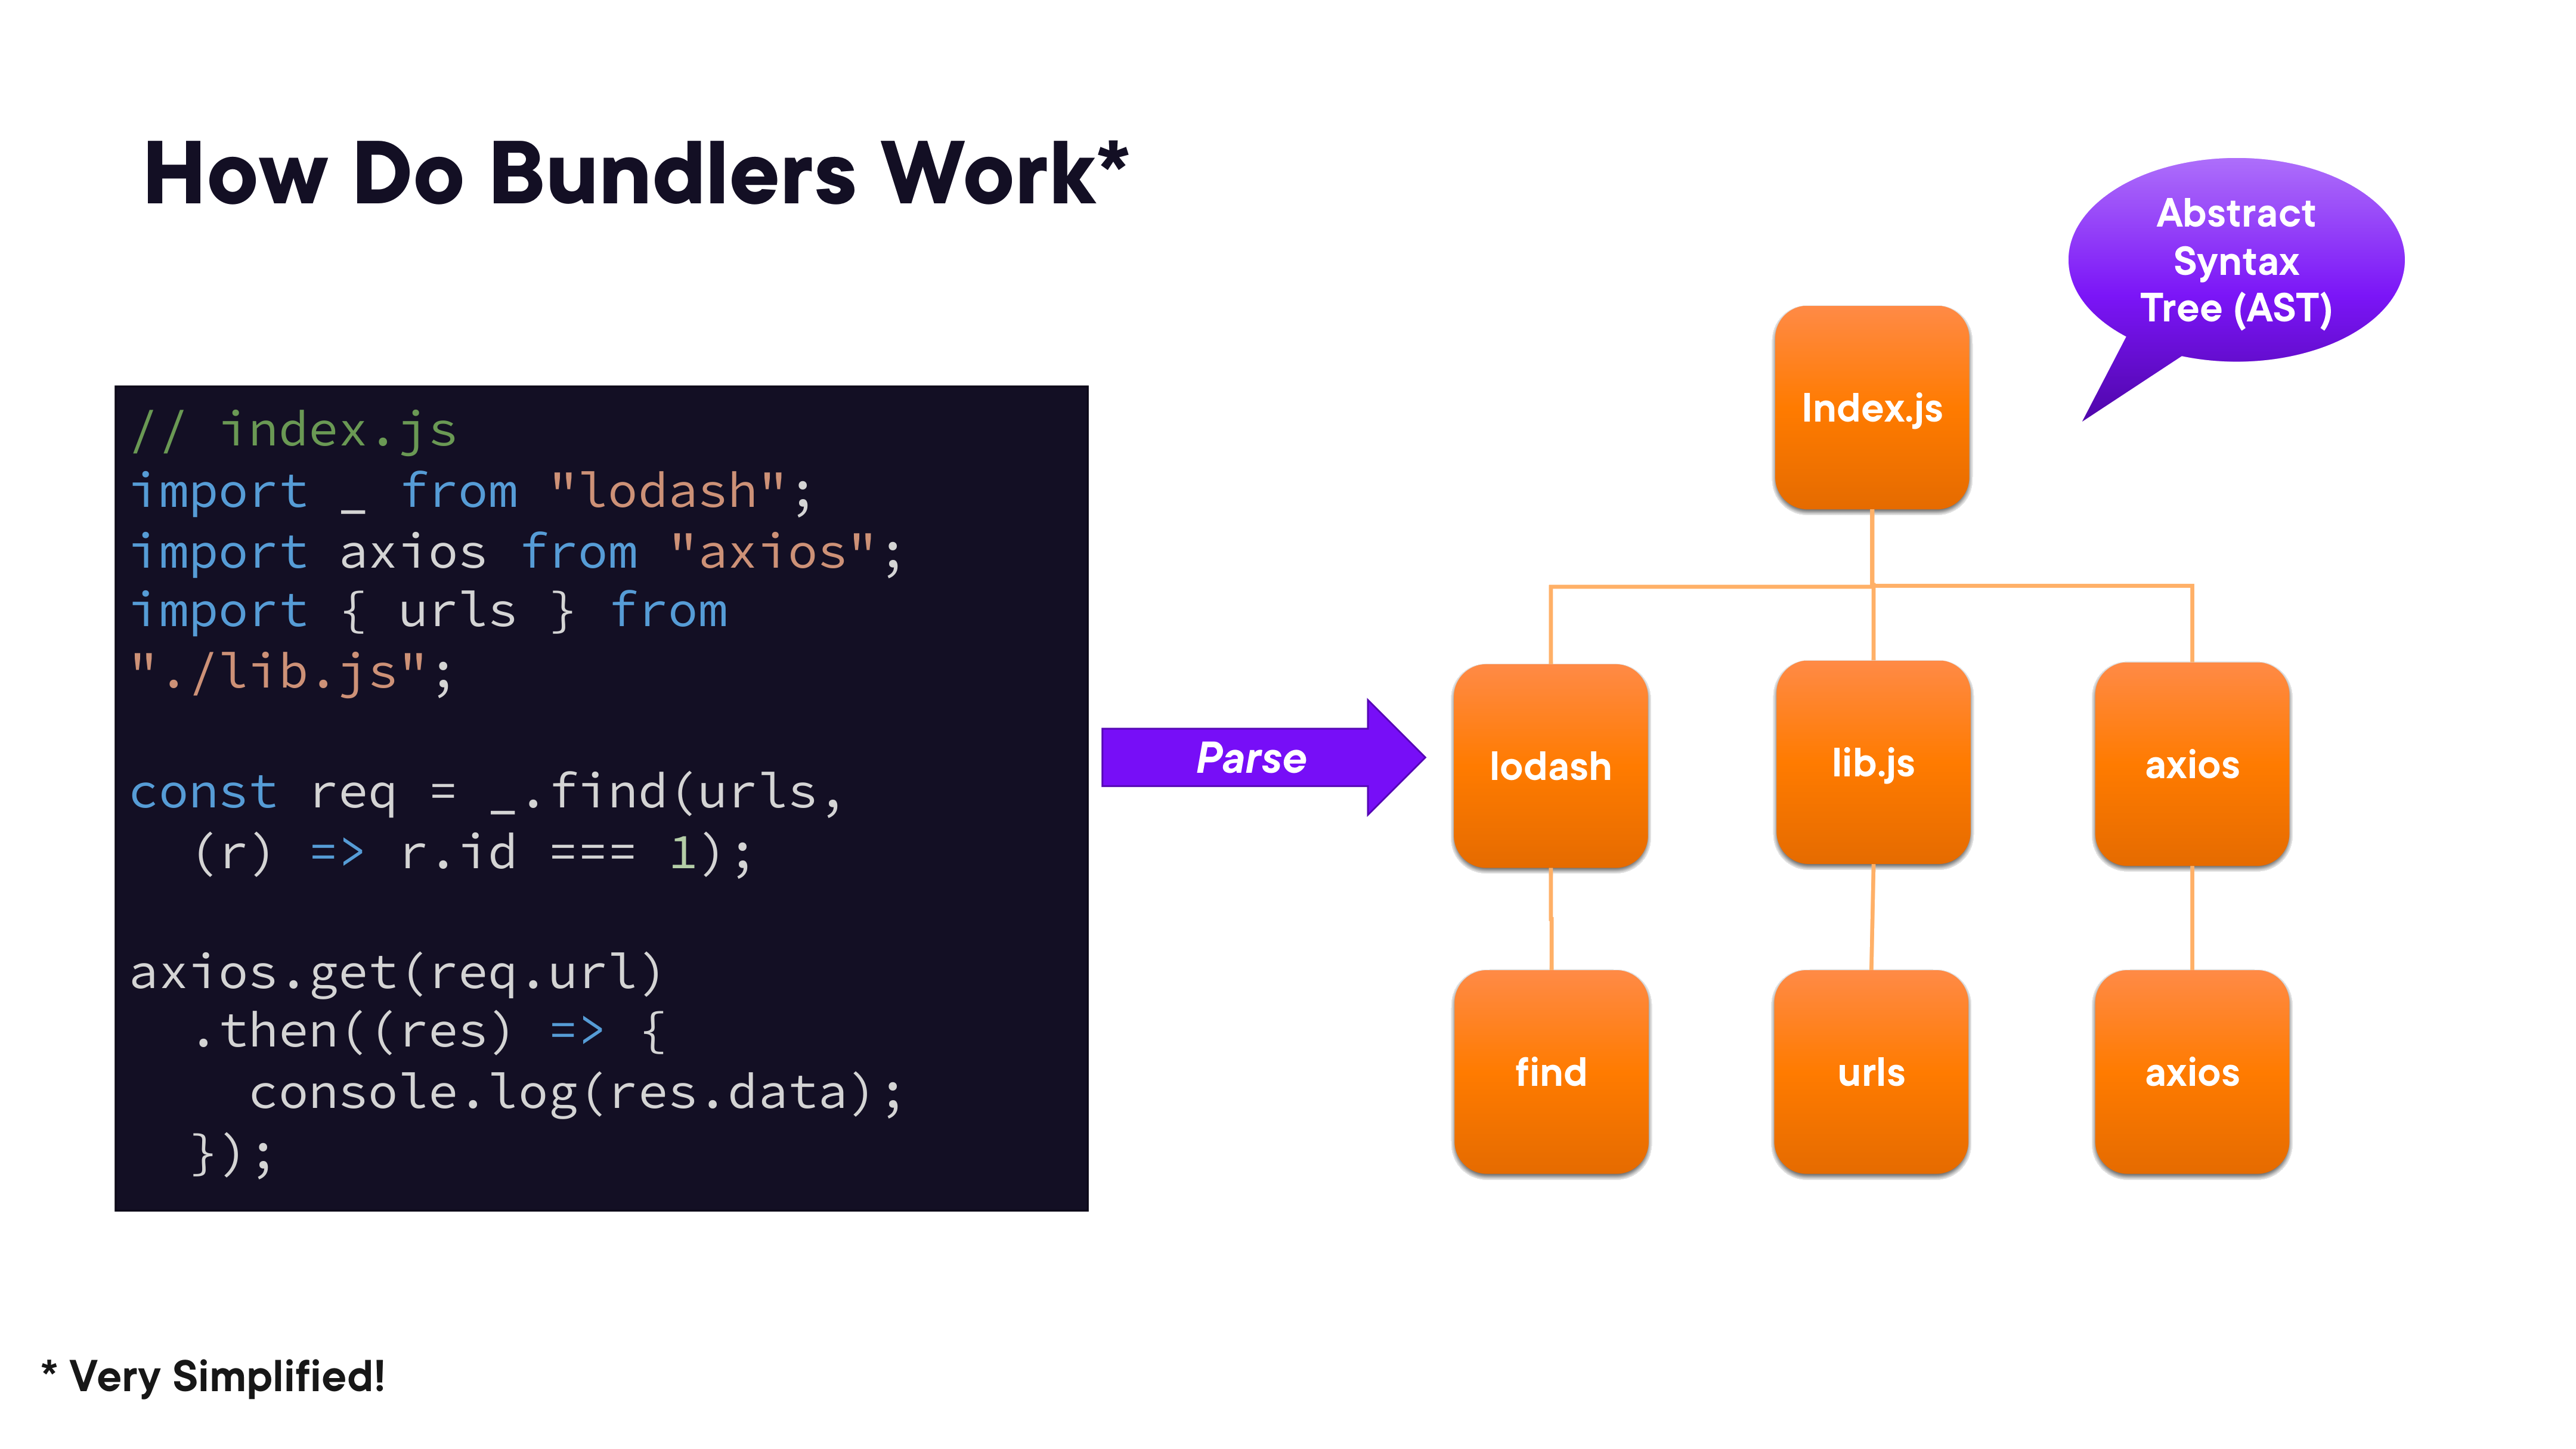

In [4]:
render_diagram(Path("assets/03-bundler-ast.png"))

#### Tree Shaking and Bundling

Once the AST is built, the bundler performs **tree shaking** — it analyses which exports are actually used and discards unused code before writing the final bundle. This is why importing only `{ find }` from lodash results in a much smaller bundle than importing all of lodash.


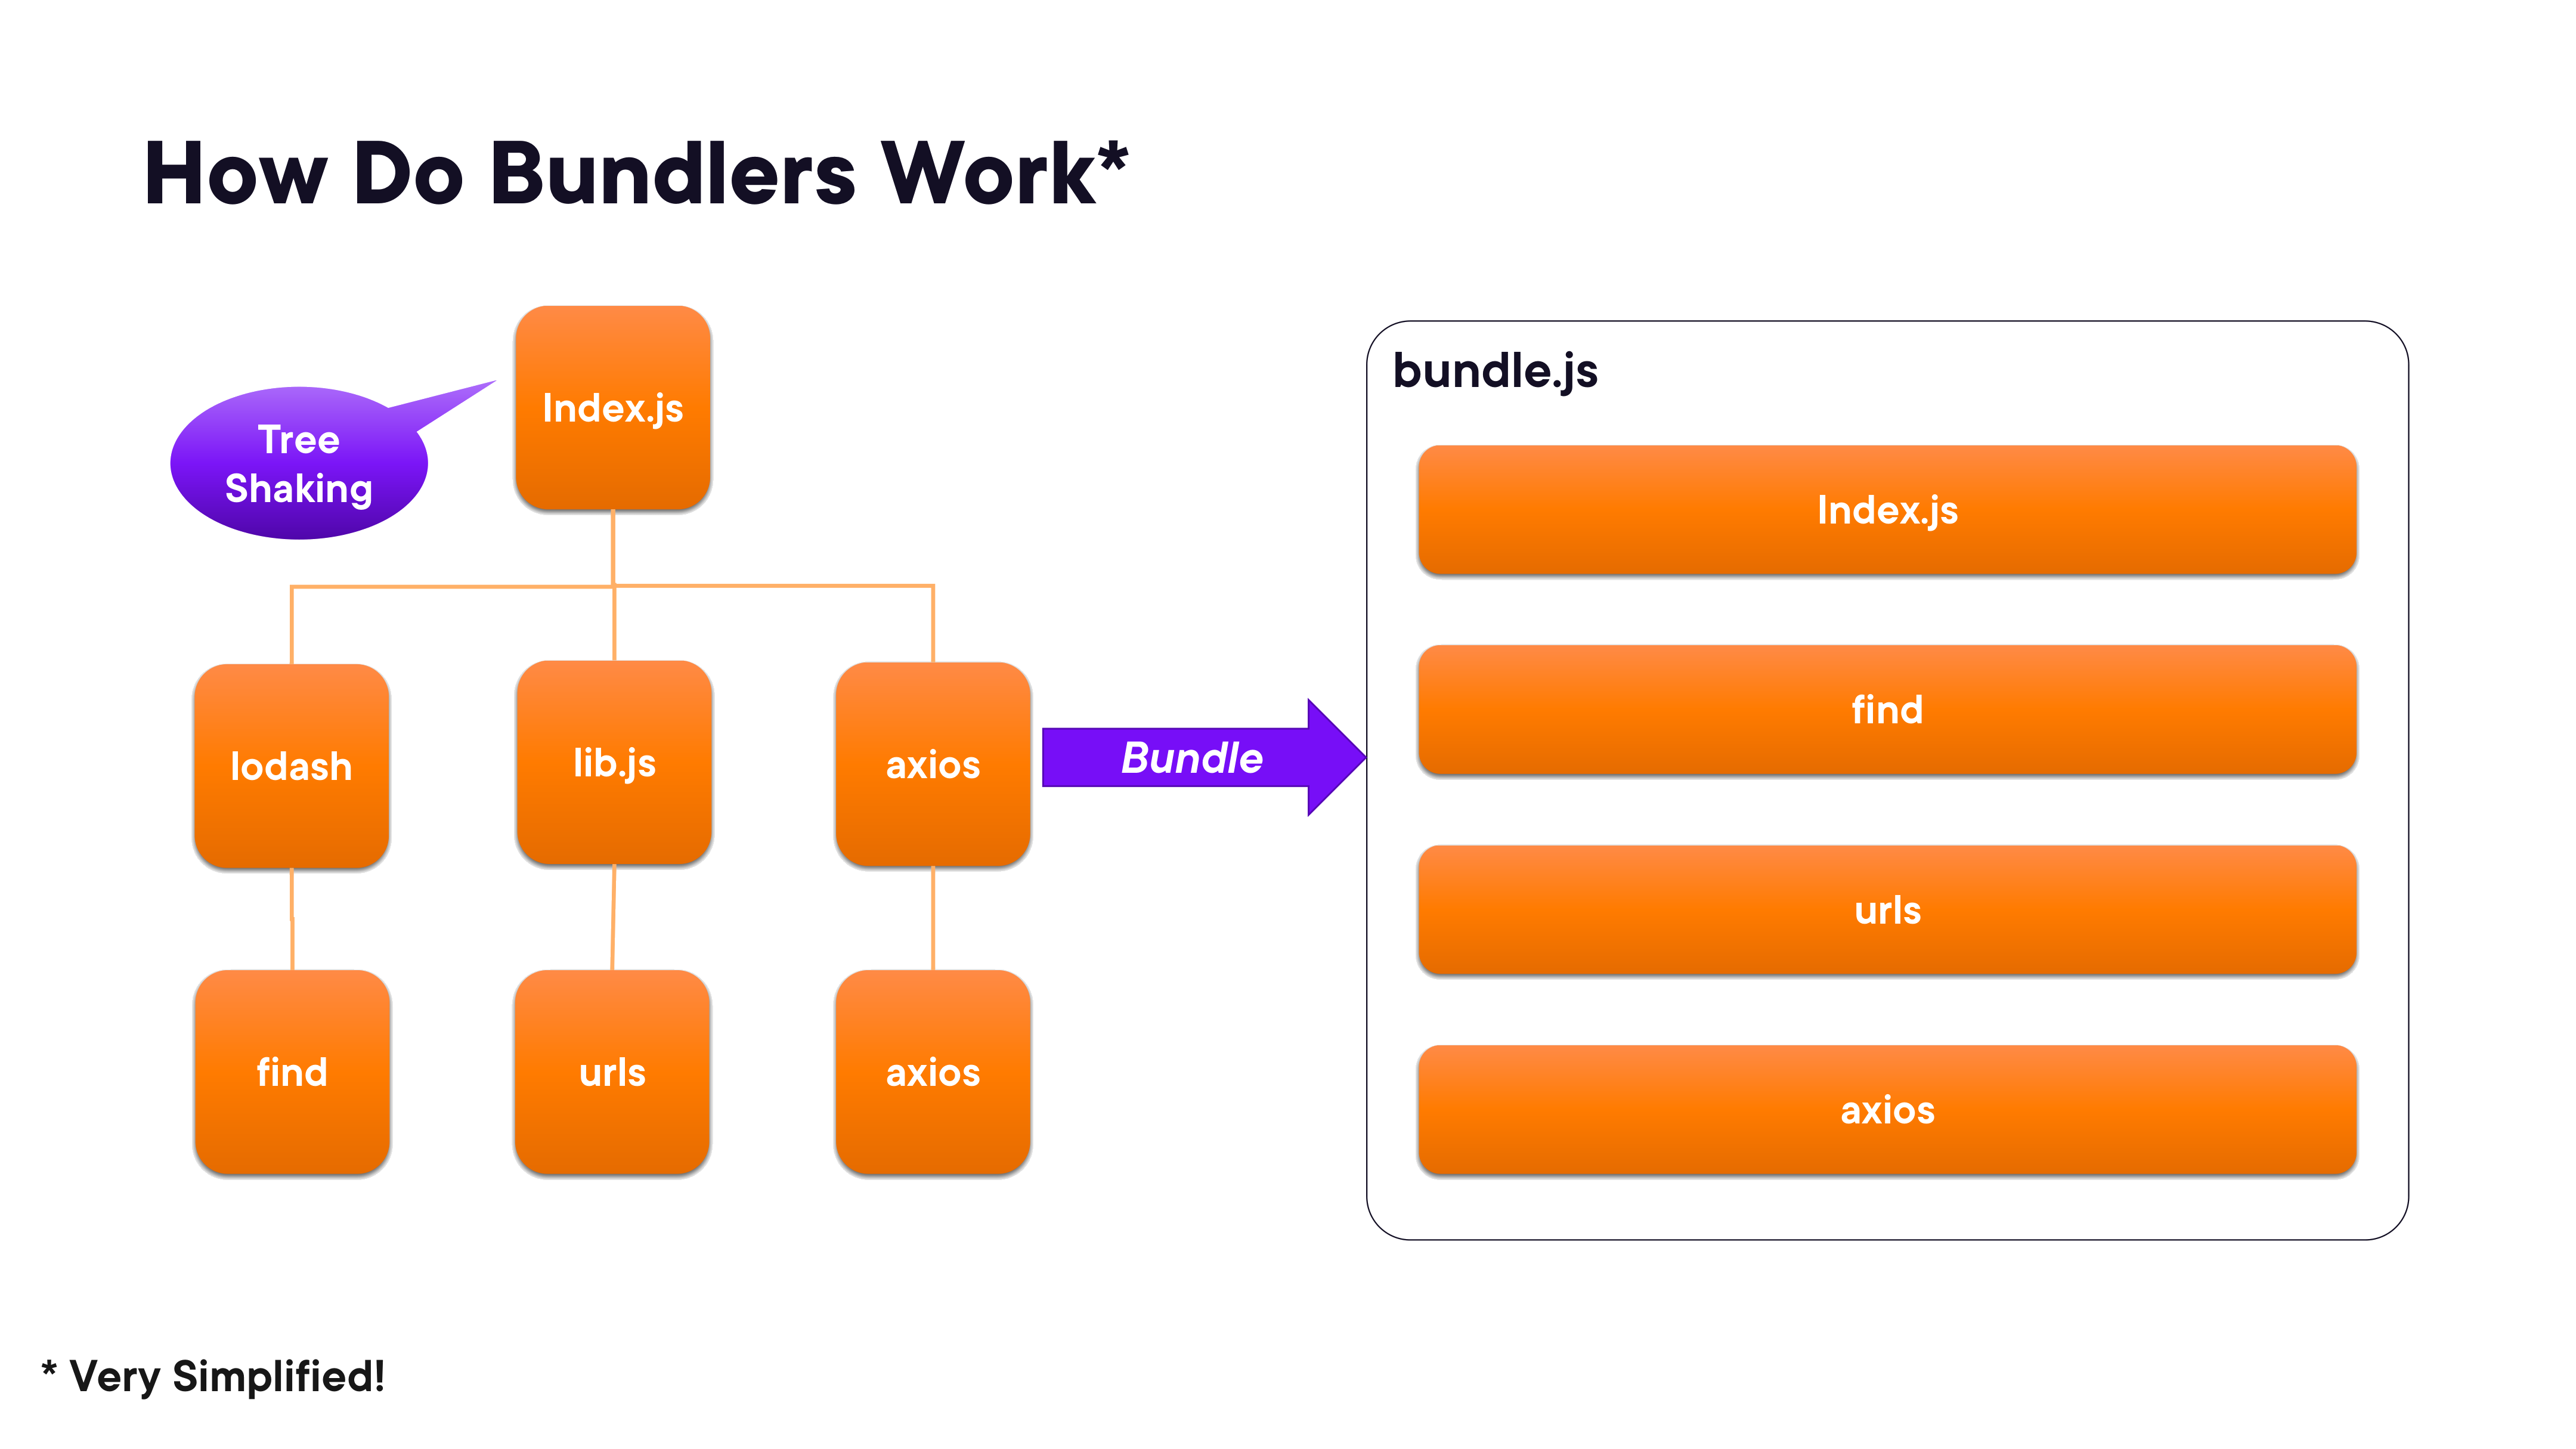

In [5]:
render_diagram(Path("assets/04-bundler-tree-shaking.png"))

#### Transpiling

Bundlers are often paired with **transpilers** that convert modern JavaScript to older syntax for broader browser compatibility:

- **Babel** — converts ES2015+ to ES5
- **TypeScript** — type-checked TypeScript to JavaScript

Transpiling is separate from bundling, but most bundler configurations integrate both in a single build step.

### The Future: Native ES Modules in the Browser

Modern browsers support ES Modules natively via `type="module"` on the `<script>` tag. This eliminates the need for a bundler in many development scenarios:

```html
<!-- The browser downloads site.js and then follows its imports automatically -->
<script src="./site.js" type="module"></script>
```

```js
// site.js
import { appName } from "./lib.js";

const title = document.getElementById("title");
title.innerHTML = appName;
```

Key behaviour of `type="module"` scripts:
- Deferred by default — runs after the document is parsed
- Has its own module scope — no global scope pollution
- Follows `import` chains, downloading all dependencies
- Supports dynamic `import()` for lazy loading

> Bundlers and transpilers still have their place for production — code splitting, polyfills, and optimisation. But for development and simple projects, native modules reduce build complexity significantly.

### Demo: Modules in the Browser

Demonstrates using a Webpack bundler and the native `type="module"` script tag for a browser app that fetches and displays data. See [`javascript-modules-demos/05-browser-modules/`](javascript-modules-demos/05-browser-modules/) for the before/after project.

The `before/` version uses plain `<script>` tags with global-scope functions. The `after/` version uses Webpack to bundle `src/index.js` (which imports `api.js` and `template.js`) into `js/main.js`:

```js
// after/src/index.js
import { appName } from "./lib.js";

const loadButton = document.getElementById("loadButton");
loadButton.addEventListener("click", async () => {
  const data = await getPassedFilms();
  createGrid(data);
});
```

Run `npm install` then `npm start` in the `after/` directory to start the Webpack dev server.